In [1]:
from sklearn.datasets import fetch_openml
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller, kpss

In [2]:
df_1h = pd.read_parquet('/Users/fangsiyu/Desktop/energy/new_data/price/price_dk1_2019-01-01_2026-08-21.parquet')
df_15 = pd.read_parquet('/Users/fangsiyu/Desktop/energy/new_data/price/price15_dk1_2025-09-30_2026-08-21.parquet')
df_1h.head()

,HourUTC,HourDK,PriceArea,SpotPriceDKK,SpotPriceEUR
0,2018-12-31 23:00:00+00:00,2019-01-01T00:00:00,DK1,211.479996,28.32
1,2019-01-01 00:00:00+00:00,2019-01-01T01:00:00,DK1,75.199997,10.07
2,2019-01-01 01:00:00+00:00,2019-01-01T02:00:00,DK1,-30.469999,-4.08
3,2019-01-01 02:00:00+00:00,2019-01-01T03:00:00,DK1,-74.000000,-9.91
4,2019-01-01 03:00:00+00:00,2019-01-01T04:00:00,DK1,-55.330002,-7.41


In [3]:
df_15.head()

,TimeUTC,TimeDK,PriceArea,DayAheadPriceEUR,DayAheadPriceDKK
0,2025-09-30 22:00:00+00:00,2025-10-01T00:00:00,DK1,102.599998,766.001325
1,2025-09-30 22:15:00+00:00,2025-10-01T00:15:00,DK1,92.239998,688.654601
2,2025-09-30 22:30:00+00:00,2025-10-01T00:30:00,DK1,86.029999,642.291370
3,2025-09-30 22:45:00+00:00,2025-10-01T00:45:00,DK1,85.389999,637.513194
4,2025-09-30 23:00:00+00:00,2025-10-01T01:00:00,DK1,89.989998,671.856326


In [4]:
df_1h = df_1h.set_index("HourUTC").sort_index()
print(df_1h.index.duplicated().sum())
print(df_1h.index.to_series().diff().value_counts())

0
HourUTC
0 days 01:00:00    59158
Name: count, dtype: int64


In [5]:
df_15 = df_15.set_index("TimeUTC").sort_index()
print(df_15.index.duplicated().sum())
print(df_15.index.to_series().diff().value_counts())

0
TimeUTC
0 days 00:15:00    31103
Name: count, dtype: int64


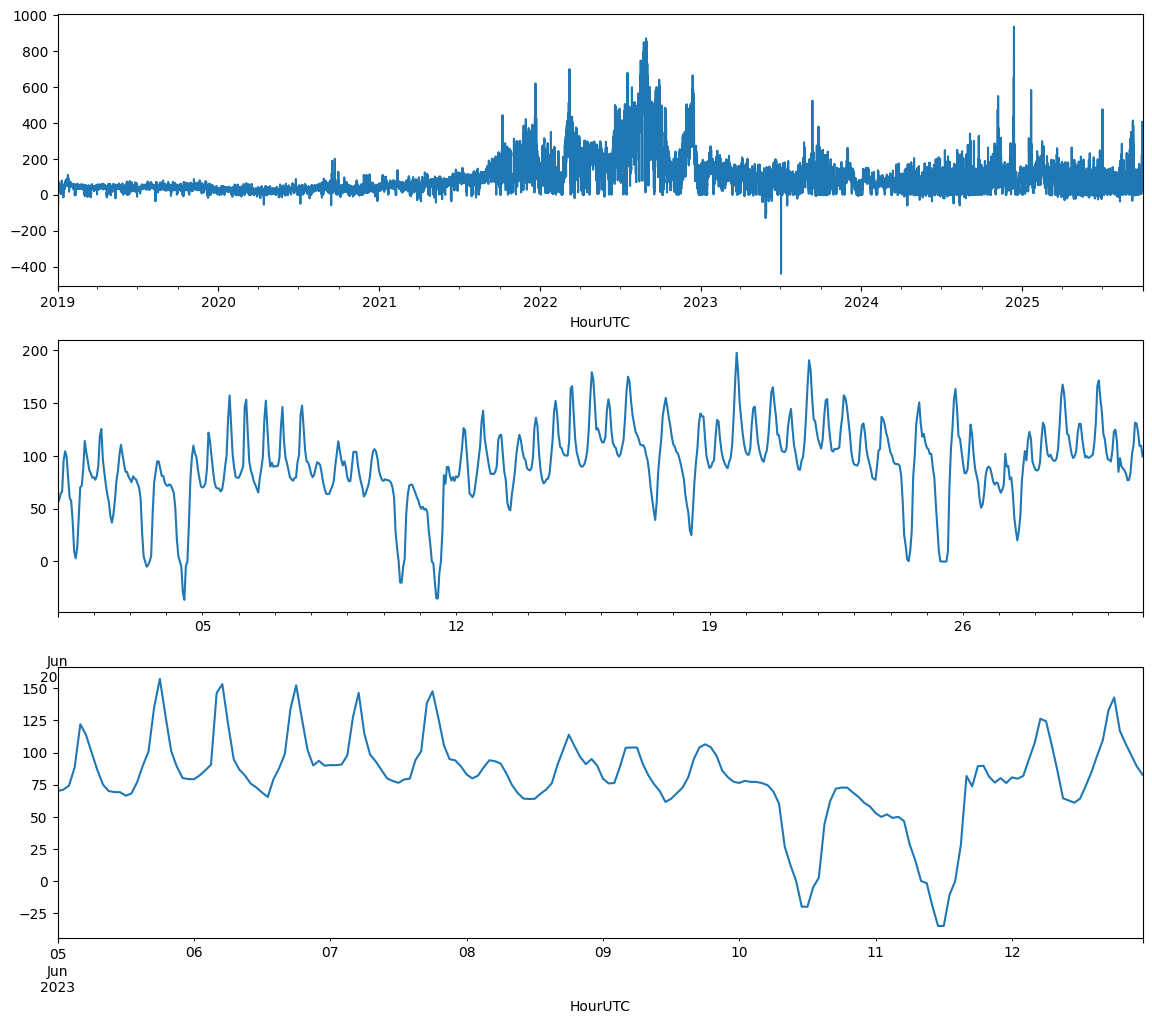

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

df_1h["SpotPriceEUR"].plot(ax=axes[0])

df_1h["SpotPriceEUR"].loc["2023-06"].plot(ax=axes[1])

df_1h["SpotPriceEUR"].loc["2023-06-05":"2023-06-12"].plot(ax=axes[2])  # 一週

plt.show()

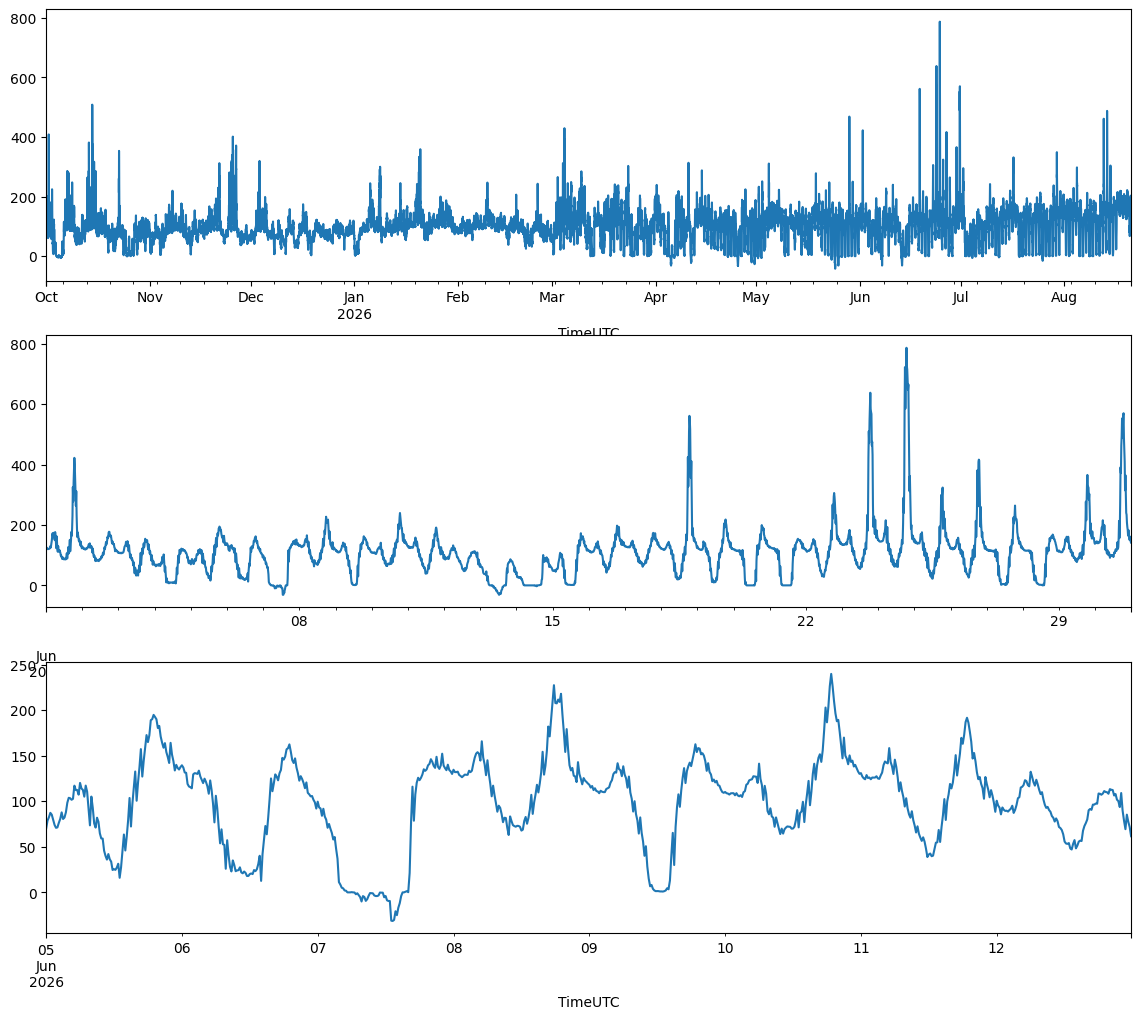

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

df_15["DayAheadPriceEUR"].plot(ax=axes[0])

df_15["DayAheadPriceEUR"].loc["2026-06"].plot(ax=axes[1])

df_15["DayAheadPriceEUR"].loc["2026-06-05":"2026-06-12"].plot(ax=axes[2])  # 一週

plt.show()

<Axes: xlabel='mean', ylabel='std'>

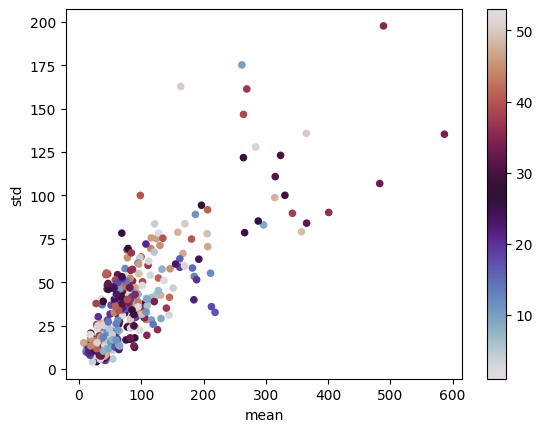

In [8]:
g = df_1h["SpotPriceEUR"].resample("W") # ME sould be month, W be week
s = pd.DataFrame({"mean": g.mean(), "std": g.std()}).dropna()
s.plot.scatter(x="mean", y="std", c=s.index.isocalendar().week, cmap="twilight")

<Axes: xlabel='mean', ylabel='std'>

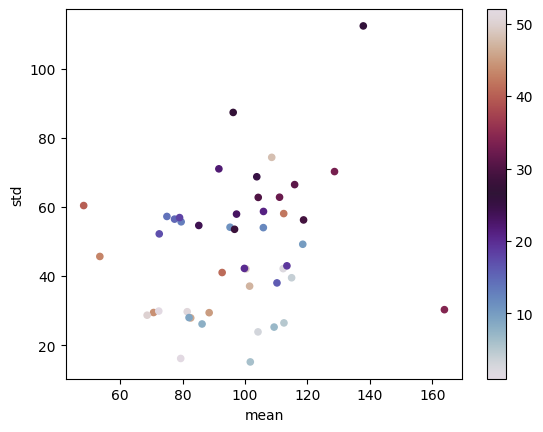

In [9]:
g = df_15["DayAheadPriceEUR"].resample("W") # ME sould be month, W be week
s = pd.DataFrame({"mean": g.mean(), "std": g.std()}).dropna()
s.plot.scatter(x="mean", y="std", c=s.index.isocalendar().week, cmap="twilight")

---
## dual-resolution pipeline

【資料層】
df_1h   : 2019-01 → 2026-08,聚合到小時(注意:2025-10 之後是四格平均)
df_15   : 2025-10 → 2026-08,原生 15 分鐘

【尺度層】
在 df_1h 上決定變換(asinh 的尺度參數 c)
→ 同一個 c 套用到 df_15

【低頻層】- 用 df_1h 估參數
年週期傅立葉 → beta_annual
週週期傅立葉 → beta_weekly
在 2019-2025 整年上估,避免月份分布不均

【高頻層】- 用 df_15 估
日內結構(15 分鐘級的 96 格 profile 或傅立葉)
短期自相關(ACF/PACF/AR 階數)

【殘差】
r_15 = transform(df_15) - s_annual(t) - s_weekly(t) - s_daily(t)
其中前兩個用借來的 beta 求值,第三個用 df_15 自己估

---
## variance-stabilizing transformation

目標是弱定態的第二個條件:變異數不隨時間變。

這邊需要一個非線性轉換。為什麼要？統計工具的前提。 ACF、ADF、AR 的估計理論都假設變異數穩定。不穩定的話,估計量的標準誤失真,信賴區間不可信。

「去除散度跟trend之間的變化」，不過在這邊我們不用 alpha 作指標，而是用 r 皮爾森積動差相關係數，把他拉成 0

In [10]:
# print(df_1h["SpotPriceEUR"].describe(percentiles=[.001, .01, .05, .25, .5, .75, .95, .99, .999]))

x = df_1h["SpotPriceEUR"]

for c in [10, 20, 30, 40, 50, 61.5, 73.4, 100.0]:
    p = pd.Series(np.arcsinh(x.values / c), index=x.index)
    g = p.resample("W")
    s = pd.DataFrame({"mean": g.mean(), "std": g.std()}).dropna()
    r = np.corrcoef(s["mean"], s["std"])[0, 1]
    print(c, round(r, 4), round(s["std"].std(), 4))

10 -0.289 0.3494
20 -0.0991 0.2626
30 0.0437 0.2205
40 0.1546 0.1947
50 0.2421 0.1768
61.5 0.3215 0.1618
73.4 0.3861 0.1498
100.0 0.4885 0.1306


In [11]:
x15 = df_15["DayAheadPriceEUR"]
for c in [30, 50, 80, 90, 100, 110, 120, 130, 140, 150, 200, 210]:
    p = pd.Series(np.arcsinh(x15.values / c), index=x15.index)
    g = p.resample("W")
    s = pd.DataFrame({"mean": g.mean(), "std": g.std()}).dropna()
    print(c, round(np.corrcoef(s["mean"], s["std"])[0, 1], 4))

30 -0.5739
50 -0.4404
80 -0.2839
90 -0.242
100 -0.2045
110 -0.171
120 -0.141
130 -0.1142
140 -0.0901
150 -0.0684
200 0.0123
210 0.0244


In [12]:
# find C work on both time series
both = pd.concat([df_1h["SpotPriceEUR"],
                  df_15["DayAheadPriceEUR"].resample("h").mean()])
# print(both.describe(percentiles=[.001, .01, .05, .25, .5, .75, .95, .99, .999]))

for c in [10, 20, 30, 40, 50, 68, 89, 110.0]:
    p = pd.Series(np.arcsinh(both / c), index=both.index)
    g = p.resample("W")
    s = pd.DataFrame({"mean": g.mean(), "std": g.std()}).dropna()
    r = np.corrcoef(s["mean"], s["std"])[0, 1]
    print(c, round(r, 4), round(s["std"].std(), 4))

10 -0.2881 0.36
20 -0.105 0.2717
30 0.0313 0.228
40 0.1372 0.2008
50 0.2211 0.1818
68 0.3337 0.1582
89 0.4247 0.1396
110.0 0.4889 0.126


In [13]:
# # 這是最佳化套件，但是沒必要在噪音上過度優化
# from scipy.optimize import brentq

# def r_of_c(c):
#     p = pd.Series(np.arcsinh(x.values / c), index=x.index)
#     g = p.resample("W")
#     s = pd.DataFrame({"mean": g.mean(), "std": g.std()}).dropna()
#     return np.corrcoef(s["mean"], s["std"])[0, 1]

# c_opt = brentq(r_of_c, 20, 40)
# print(c_opt) # 26.65354238181838

In [14]:
# 設定這是因為我們要鎖定一個所有共用的，不能分年段也不能分時段去找這參數，這不合法
C_PRICE = 30.0

# 前處理層尺度參數。工作:壓縮尖峰,讓季節配適與 AR 估計不被極端值主導。
# 選法:掃描使週 mean 與週 std 的 Pearson r → 0。全樣本零交叉點 ≈ 28,取整數 30。
#
# 已知限制:df_15 段(2025-10 起)單獨掃描的零交叉點 ≈ 195,相差約 7 倍。
# 原因:2022 能源危機後價格尺度整體上移(見分年 median 表)。
# 仍共用 c=30:低頻季節參數需從 1h 段借給 15min 段,兩段必須同尺度。
# 代價:df_15 段 r = -0.574(過度壓縮),該段變異數估計略偏。
# 變換不丟資訊(asinh 單調可逆),極端值仍完整保留在資料中。
# 訓練範圍與極端值權重屬模型層決策,不在此處鎖定。

In [18]:
g = p_1h.resample("W")
s = pd.DataFrame({"mean": g.mean(), "std": g.std()}).dropna()
print(s.groupby(s.index.year).apply(
    lambda x: np.corrcoef(x["mean"], x["std"])[0,1]).round(3))

HourUTC
2019   -0.495
2020   -0.116
2021    0.025
2022   -0.580
2023   -0.797
2024   -0.253
2025   -0.804
dtype: float64


但是我們推出來的分段 r 提供理由拒絕這轉換後的東西。總言之，這level 不隨時間轉變無法拒絕

---
## Low frequence

In [22]:
p_1h = pd.Series(np.arcsinh(df_1h["SpotPriceEUR"].values / C_PRICE),
                 index=df_1h.index)
p_15 = pd.Series(np.arcsinh(df_15["DayAheadPriceEUR"].values / C_PRICE),
                 index=df_15.index)
p_both = pd.Series(np.arcsinh(both.values / C_PRICE), index=both.index)


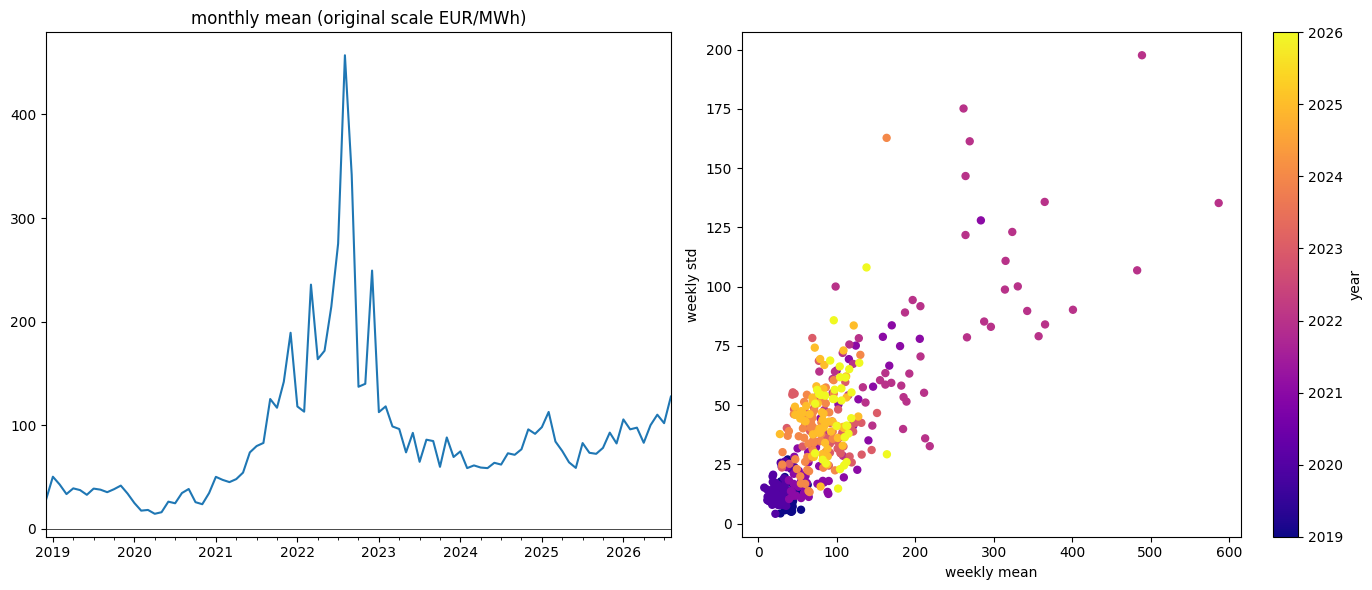

In [23]:
gb = both.resample("W")
s_both = pd.DataFrame({"mean": gb.mean(), "std": gb.std()}).dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

both.resample("ME").mean().plot(ax=axes[0])
axes[0].axhline(0, color="k", lw=0.5)
axes[0].set_title("monthly mean (original scale EUR/MWh)")

sc = axes[1].scatter(s_both["mean"], s_both["std"],
                     c=s_both.index.year, cmap="plasma", s=25)
plt.colorbar(sc, ax=axes[1], label="year")
axes[1].set_xlabel("weekly mean")
axes[1].set_ylabel("weekly std")

plt.tight_layout()
plt.show()

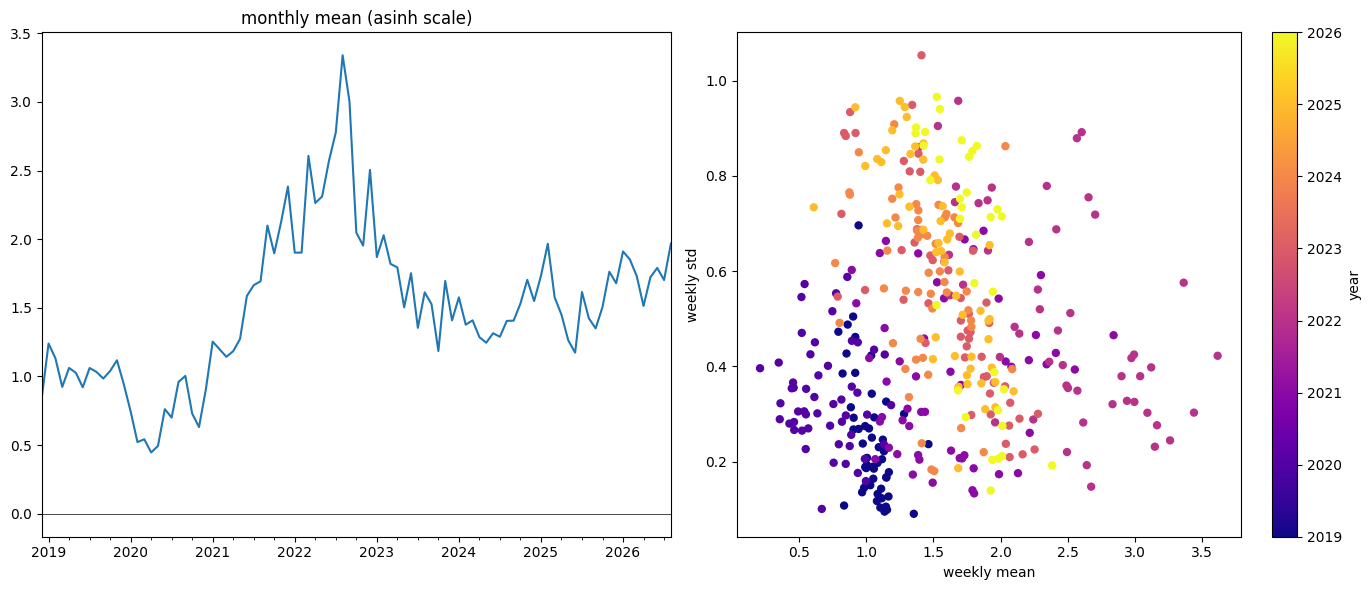

In [26]:
gb = p_both.resample("W")
s_both = pd.DataFrame({"mean": gb.mean(), "std": gb.std()}).dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

p_both.resample("ME").mean().plot(ax=axes[0])
axes[0].axhline(0, color="k", lw=0.5)
axes[0].set_title("monthly mean (asinh scale)")

sc = axes[1].scatter(s_both["mean"], s_both["std"],
                     c=s_both.index.year, cmap="plasma", s=25)
plt.colorbar(sc, ax=axes[1], label="year")
axes[1].set_xlabel("weekly mean")
axes[1].set_ylabel("weekly std")

plt.tight_layout()
plt.show()

array([<Axes: >, <Axes: >], dtype=object)

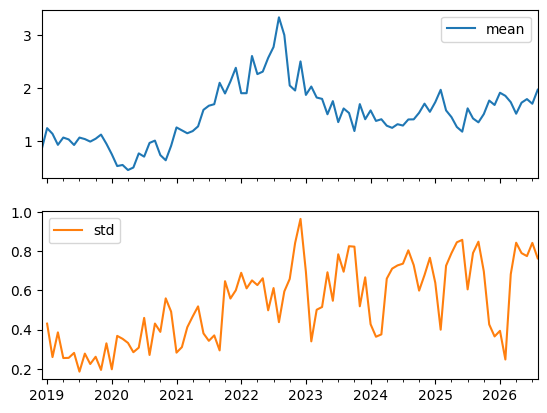

In [27]:
m = p_both.resample("ME")
pd.DataFrame({"mean": m.mean(), "std": m.std()}).plot(subplots=True)

In [28]:
p = p_both

r_m  = p - p.groupby(p.index.month).transform("mean")
r_h  = p - p.groupby(p.index.hour).transform("mean")
r_d  = p - p.groupby(p.index.dayofweek).transform("mean")
r_y  = p - p.groupby(p.index.year).transform("mean")
r_mh = p - p.groupby([p.index.month, p.index.hour]).transform("mean")
r_dh = p - p.groupby([p.index.dayofweek, p.index.hour]).transform("mean")

for name, res in [("month", r_m), ("hour", r_h), ("dayofweek", r_d),
                  ("year", r_y), ("month&hour", r_mh), ("dow&hour", r_dh)]:
    print(name, round(1 - res.var()/p.var(), 5))

month 0.01418
hour 0.05716
dayofweek 0.02745
year 0.37338
month&hour 0.11322
dow&hour 0.09645
